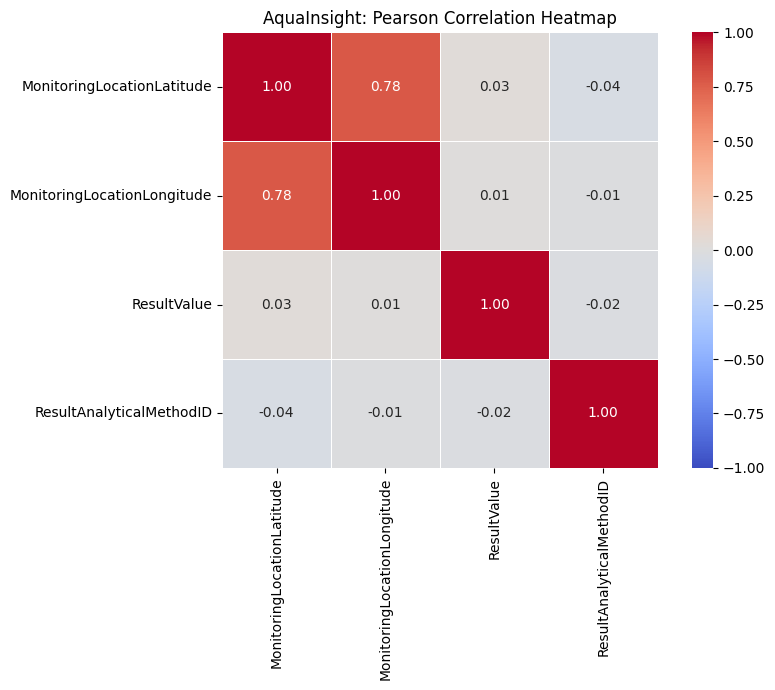

Heatmap saved as: correlation_heatmap.png

Strong feature pairs (absolute correlation >= 0.8):
No pairs crossed the selected cutoff.

Interpretation: values close to +1 indicate a strong positive relationship; values close to -1 indicate a strong negative relationship; values near 0 indicate a weak relationship of the type measured by the selected method. Correlation does not prove causation. Investigate highly correlated features before removing anything.


In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

METHOD = "pearson"               # Options: "pearson", "spearman", "kendall"
OUTPUT_FILE = "correlation_heatmap.png"
CORRELATION_CUTOFF = 0.80

df = pd.read_csv("Water Quality.csv")  
numeric_df = df.select_dtypes(include="number").copy()
numeric_df = numeric_df.loc[:, numeric_df.nunique(dropna=True) > 1]

if numeric_df.shape[1] < 2:
    raise ValueError("At least two varying numerical columns are required.")

# Pearson measures linear relationships; Spearman and Kendall use ranks
corr = numeric_df.corr(method=METHOD)

plt.figure(figsize=(max(9, len(corr.columns) * 0.8),
                    max(7, len(corr.columns) * 0.65)))
sns.heatmap(
    corr,
    annot=(len(corr.columns) <= 15),
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.4
)
plt.title(f"AquaInsight: {METHOD.title()} Correlation Heatmap")
plt.tight_layout()
plt.savefig(OUTPUT_FILE, dpi=300, bbox_inches="tight")
plt.show()

# List strongly correlated feature pairs, without duplicate pairs
strong_pairs = []
columns = corr.columns
for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        value = corr.iloc[i, j]
        if pd.notna(value) and abs(value) >= CORRELATION_CUTOFF:
            strong_pairs.append((columns[i], columns[j], value))

print(f"Heatmap saved as: {OUTPUT_FILE}")
print(f"\nStrong feature pairs (absolute correlation >= {CORRELATION_CUTOFF}):")
if strong_pairs:
    for first, second, value in sorted(strong_pairs, key=lambda x: abs(x[2]), reverse=True):
        print(f"{first} <-> {second}: {value:.3f}")
else:
    print("No pairs crossed the selected cutoff.")

print(
    "\nInterpretation: values close to +1 indicate a strong positive relationship; "
    "values close to -1 indicate a strong negative relationship; values near 0 "
    "indicate a weak relationship of the type measured by the selected method. "
    "Correlation does not prove causation. Investigate highly correlated features "
    "before removing anything."
)
